In [1]:
print("My First Machine Learning Project")
print("Student Performance Prediction")

My First Machine Learning Project
Student Performance Prediction


In [2]:
import numpy as np

study_hours = np.array([1, 2, 3, 4, 5])
marks = np.array([25, 35, 45, 55, 65])

print("Study Hours:", study_hours)
print("Marks:", marks)
print("Average Marks:", np.mean(marks))

Study Hours: [1 2 3 4 5]
Marks: [25 35 45 55 65]
Average Marks: 45.0


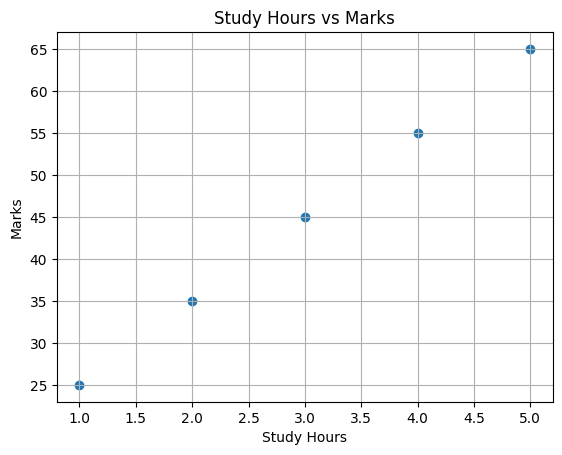

In [3]:
import matplotlib.pyplot as plt

plt.scatter(study_hours, marks)

plt.xlabel("Study Hours")
plt.ylabel("Marks")

plt.title("Study Hours vs Marks")
plt.grid(True)

plt.show()

In [5]:
import numpy as np

# Step 1: Calculate the mean of X and Y
x_mean = np.mean(study_hours)
y_mean = np.mean(marks)

# Step 2: Calculate slope (b1)
numerator = np.sum(
    (study_hours - x_mean) * (marks - y_mean)
)

denominator = np.sum(
    (study_hours - x_mean) ** 2
)

b1 = numerator / denominator

# Step 3: Calculate intercept (b0)
b0 = y_mean - b1 * x_mean

# Step 4: Show the trained model
print("Slope:", b1)
print("Intercept:", b0)
print("Model: Marks =", b0, "+", b1, "* Study Hours")

# Step 5: Predict marks for 6 study hours
new_hours = 6
predicted_marks = b0 + b1 * new_hours

print("Predicted marks for 6 hours:", predicted_marks)

Slope: 10.0
Intercept: 15.0
Model: Marks = 15.0 + 10.0 * Study Hours
Predicted marks for 6 hours: 75.0


In [6]:
# Predict marks for all existing study hours
predictions = b0 + b1 * study_hours

# Calculate errors
errors = marks - predictions

# Mean Absolute Error (MAE)
mae = np.mean(np.abs(errors))

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(np.mean(errors ** 2))

# R-squared (R²)
ss_res = np.sum(errors ** 2)
ss_tot = np.sum((marks - np.mean(marks)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("Actual Marks:", marks)
print("Predicted Marks:", predictions)
print("MAE:", mae)
print("RMSE:", rmse)
print("R-squared:", r2)

Actual Marks: [25 35 45 55 65]
Predicted Marks: [25. 35. 45. 55. 65.]
MAE: 0.0
RMSE: 0.0
R-squared: 1.0


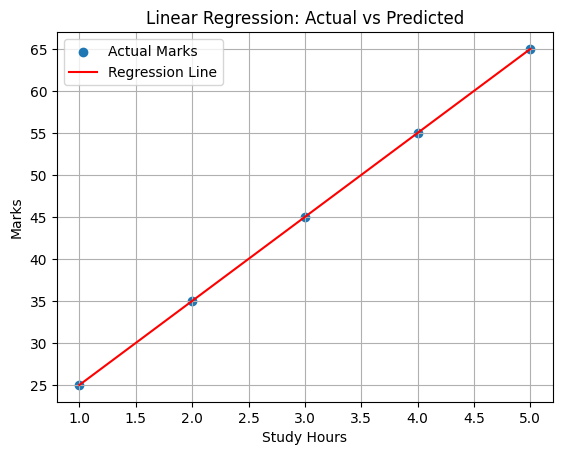

In [7]:
import matplotlib.pyplot as plt

plt.scatter(study_hours, marks, label="Actual Marks")

plt.plot(
    study_hours,
    predictions,
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
import pandas as pd

url = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset size:", df.shape)

df.head()

Dataset loaded successfully!
Dataset size: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [9]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFinal grade summary:")
print(df["G3"].describe())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0

Final grade summary:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

# Select input features
X = df[["studytime", "failures", "absences", "G1", "G2"]]

# Select the value we want to predict
y = df["G3"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training input shape: (316, 5)
Testing input shape: (79, 5)
Training records: 316
Testing records: 79


In [11]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict marks for test students
y_pred = model.predict(X_test)

# Calculate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Actual Marks:", y_test.values[:10])
print("Predicted Marks:", np.round(y_pred[:10], 2))

print("\nModel Performance")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 3))

Actual Marks: [10 12  5 10  9 13 18  6  0 14]
Predicted Marks: [ 6.01 12.2   3.43  8.52  7.87 12.7  18.69  7.1   7.23 12.64]

Model Performance
MAE: 1.34
RMSE: 2.11
R-squared: 0.782


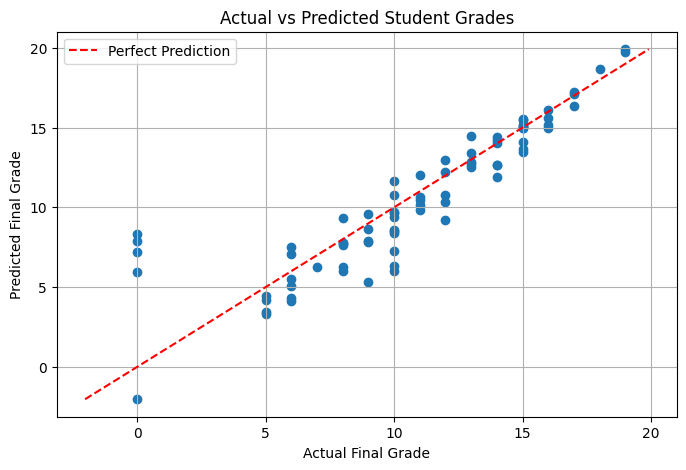

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Perfect predictions ki reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")
plt.legend()
plt.grid(True)
plt.show()

# Student Performance Prediction using Linear Regression

## Project Overview
This project uses Linear Regression to predict students' final grades using the UCI Student Performance dataset.

## Features Used
- Study time
- Previous failures
- Absences
- First-period grade (G1)
- Second-period grade (G2)

## Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Google Colab

## Model Evaluation
The model is evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

## Current Results
- MAE: 1.34
- RMSE: 2.11
- R²: 0.782

## Learning Outcomes
- Loading and exploring a real-world dataset
- Splitting data into training and testing sets
- Training a Linear Regression model
- Evaluating predictions and visualizing results

**Note:** Results are based on one train-test split and may vary with different data splits. This model is for educational purposes and should not be used to make high-stakes decisions about students.
